# 6.1 — Load the cleaned crime data and grid information

## Imports

In [1]:
import pandas as pd
import numpy as np
import os

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

## Load the cleaned crime data

In [2]:
crime_df = pd.read_csv(
    "data/chicago_crime_cleaned.csv"
)

print("Crime dataset loaded.")
print("Shape:", crime_df.shape)

display(crime_df.head())

Crime dataset loaded.
Shape: (228595, 17)


,CASE#,DATE_OF_OCCURRENCE,BLOCK,IUCR,PRIMARY_DESCRIPTION,SECONDARY_DESCRIPTION,LOCATION_DESCRIPTION,ARREST,DOMESTIC,BEAT,WARD,FBI_CD,X_COORDINATE,Y_COORDINATE,LATITUDE,LONGITUDE,LOCATION
0,JJ387233,2025-08-24 05:03:00,029XX W 25TH PL,0486,BATTERY,DOMESTIC BATTERY SIMPLE,RESIDENCE,Y,Y,1033,24.0,08B,1157153.0,1886939.0,41.845527,-87.698757,"(41.845527098, -87.698756503)"
1,JJ387253,2025-08-24 05:25:00,070XX S JEFFERY BLVD,0460,BATTERY,SIMPLE,STREET,N,N,331,5.0,08B,1190765.0,1858575.0,41.766947,-87.576322,"(41.766946791, -87.57632241)"
2,JJ387811,2025-08-24 05:30:00,102XX S OAKLEY AVE,0620,BURGLARY,UNLAWFUL ENTRY,RESIDENCE - GARAGE,N,N,2213,19.0,05,1162636.0,1836625.0,41.707346,-87.680037,"(41.707345681, -87.680037133)"
3,JJ387309,2025-08-24 05:30:00,027XX N CALIFORNIA AVE,0760,BURGLARY,BURGLARY FROM MOTOR VEHICLE,PARKING LOT / GARAGE (NON RESIDENTIAL),N,N,1411,1.0,06,1157241.0,1918050.0,41.930897,-87.697588,"(41.930896787, -87.697587655)"
4,JJ387926,2025-08-24 05:32:00,028XX W 55TH ST,1310,CRIMINAL DAMAGE,TO PROPERTY,SMALL RETAIL STORE,N,N,824,15.0,14,1158561.0,1868058.0,41.793687,-87.694105,"(41.793686636, -87.694104755)"


## Load the grid/node information

In [3]:
grid_nodes = pd.read_csv(
    "data/chicago_spatial_grid.csv"
)

print("Grid data loaded.")
print("Shape:", grid_nodes.shape)

display(grid_nodes.head())

Grid data loaded.
Shape: (157, 6)


,GRID_ID,GRID_ROW,GRID_COL,GRID_CENTER_LAT,GRID_CENTER_LON,CRIME_COUNT
0,0_9,0,9,41.654160,-87.644006,218
1,0_10,0,10,41.654305,-87.617586,595
2,0_11,0,11,41.654444,-87.591166,559
3,0_12,0,12,41.654577,-87.564745,121
4,0_13,0,13,41.654704,-87.538324,451


## Load the coordinate conversion tools

In [4]:
from pyproj import Transformer

# Convert Chicago latitude/longitude to the same projected
# coordinate system used for the grid.

transformer = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:26916",
    always_xy=True
)

print("Coordinate transformer created.")

Coordinate transformer created.


## Convert crime coordinates to projected coordinates

In [5]:
crime_df["X_M"], crime_df["Y_M"] = transformer.transform(
    crime_df["LONGITUDE"].values,
    crime_df["LATITUDE"].values
)

print("Projected coordinates created.")

display(
    crime_df[
        ["LATITUDE", "LONGITUDE", "X_M", "Y_M"]
    ].head()
)

Projected coordinates created.


,LATITUDE,LONGITUDE,X_M,Y_M
0,41.845527,-87.698757,441990.739717,4.632861e+06
1,41.766947,-87.576322,452096.495146,4.624062e+06
2,41.707346,-87.680037,443423.472159,4.617507e+06
3,41.930897,-87.697588,442164.830408,4.642339e+06
4,41.793687,-87.694105,442330.424984,4.627103e+06


## Check the projected ranges

In [6]:
print("Projected X range:")
print(
    crime_df["X_M"].min(),
    "to",
    crime_df["X_M"].max()
)

print()

print("Projected Y range:")
print(
    crime_df["Y_M"].min(),
    "to",
    crime_df["Y_M"].max()
)

Projected X range:
425476.99038882746 to 456357.7255699687

Projected Y range:
4610479.474780203 to 4652500.76689099


# 6.2 — Assign each crime record to its existing grid cell

## Define the grid parameters

In [7]:
# Same grid definition used in the previous notebook

GRID_SIZE = 2200  # approximately 2.2 km

MIN_X = 425476.99038882746
MIN_Y = 4610479.474780203

print("Grid size:", GRID_SIZE, "meters")
print("Minimum X:", MIN_X)
print("Minimum Y:", MIN_Y)

Grid size: 2200 meters
Minimum X: 425476.99038882746
Minimum Y: 4610479.474780203


## Calculate grid row and column

In [8]:
crime_df["GRID_ROW"] = (
    np.floor(
        (crime_df["Y_M"] - MIN_Y) / GRID_SIZE
    ).astype(int)
)

crime_df["GRID_COL"] = (
    np.floor(
        (crime_df["X_M"] - MIN_X) / GRID_SIZE
    ).astype(int)
)

crime_df["GRID_ID"] = (
    crime_df["GRID_ROW"].astype(str)
    + "_"
    + crime_df["GRID_COL"].astype(str)
)

print("Grid assignment completed.")

display(
    crime_df[
        [
            "LATITUDE",
            "LONGITUDE",
            "X_M",
            "Y_M",
            "GRID_ROW",
            "GRID_COL",
            "GRID_ID"
        ]
    ].head(10)
)

Grid assignment completed.


,LATITUDE,LONGITUDE,X_M,Y_M,GRID_ROW,GRID_COL,GRID_ID
0,41.845527,-87.698757,441990.739717,4.632861e+06,10,7,10_7
1,41.766947,-87.576322,452096.495146,4.624062e+06,6,12,6_12
2,41.707346,-87.680037,443423.472159,4.617507e+06,3,8,3_8
3,41.930897,-87.697588,442164.830408,4.642339e+06,14,7,14_7
4,41.793687,-87.694105,442330.424984,4.627103e+06,7,7,7_7
5,41.773085,-87.568335,452764.874951,4.624739e+06,6,12,6_12
6,41.808899,-87.643515,446546.366313,4.628759e+06,8,9,8_9
7,41.833364,-87.617008,448767.629780,4.631459e+06,9,10,9_10
8,41.747758,-87.652451,445752.523296,4.621976e+06,5,9,5_9
9,41.909664,-87.742729,438401.854957,4.640013e+06,13,5,13_5


## Check the number of grid IDs

In [9]:
unique_crime_grids = crime_df["GRID_ID"].nunique()

print(
    "Unique grid cells assigned to crime records:",
    unique_crime_grids
)

print(
    "Grid cells in grid_nodes:",
    grid_nodes["GRID_ID"].nunique()
)

Unique grid cells assigned to crime records: 157
Grid cells in grid_nodes: 157


## Check for unmatched grid cells

In [10]:
crime_grid_ids = set(
    crime_df["GRID_ID"].unique()
)

node_grid_ids = set(
    grid_nodes["GRID_ID"].unique()
)

crime_not_in_nodes = crime_grid_ids - node_grid_ids
nodes_without_crimes = node_grid_ids - crime_grid_ids

print(
    "Crime grid IDs not found in grid_nodes:",
    len(crime_not_in_nodes)
)

print(
    "Grid nodes without crime records:",
    len(nodes_without_crimes)
)

Crime grid IDs not found in grid_nodes: 0
Grid nodes without crime records: 0


## Verify crime counts

In [11]:
crime_counts_check = (
    crime_df
    .groupby("GRID_ID")
    .size()
    .reset_index(name="CALCULATED_COUNT")
)

verification = grid_nodes.merge(
    crime_counts_check,
    on="GRID_ID",
    how="left"
)

verification["DIFFERENCE"] = (
    verification["CRIME_COUNT"]
    - verification["CALCULATED_COUNT"]
)

display(
    verification[
        [
            "GRID_ID",
            "CRIME_COUNT",
            "CALCULATED_COUNT",
            "DIFFERENCE"
        ]
    ].head(20)
)

,GRID_ID,CRIME_COUNT,CALCULATED_COUNT,DIFFERENCE
0,0_9,218,218,0
1,0_10,595,595,0
2,0_11,559,559,0
3,0_12,121,121,0
4,0_13,451,451,0
5,1_6,2,2,0
6,1_7,25,25,0
7,1_8,441,441,0
8,1_9,1332,1332,0
9,1_10,1181,1181,0


## Confirm all counts match

In [12]:
print(
    "Maximum absolute difference:",
    verification["DIFFERENCE"].abs().max()
)

print(
    "Number of grid cells with mismatched counts:",
    (
        verification["DIFFERENCE"] != 0
    ).sum()
)

Maximum absolute difference: 0
Number of grid cells with mismatched counts: 0


# 6.3 — Temporal features and crime-type preparation

## 6.3.1 — Prepare temporal and crime-type features

In [13]:
# Step 6.3.1 — Prepare temporal and crime-type features

# Make a copy so the original cleaned dataframe stays unchanged
crime_features = crime_df.copy()

# Convert date column to datetime
crime_features["DATE_OF_OCCURRENCE"] = pd.to_datetime(
    crime_features["DATE_OF_OCCURRENCE"],
    errors="coerce"
)

# Create temporal features
crime_features["YEAR"] = crime_features["DATE_OF_OCCURRENCE"].dt.year
crime_features["MONTH"] = crime_features["DATE_OF_OCCURRENCE"].dt.month
crime_features["MONTH_NAME"] = crime_features["DATE_OF_OCCURRENCE"].dt.month_name()
crime_features["DAY_OF_WEEK"] = crime_features["DATE_OF_OCCURRENCE"].dt.day_name()
crime_features["HOUR"] = crime_features["DATE_OF_OCCURRENCE"].dt.hour

# Count each crime type
crime_type_counts = crime_features["PRIMARY_DESCRIPTION"].value_counts()

# Research-paper rule:
# Crime types with fewer than 1,000 incidents -> OTHER
rare_crimes = crime_type_counts[crime_type_counts < 1000].index

crime_features["CRIME_TYPE"] = crime_features["PRIMARY_DESCRIPTION"].replace(
    rare_crimes,
    "OTHER"
)

print("Total crime records:", len(crime_features))
print("Rare crime categories grouped into OTHER:", len(rare_crimes))
print("\nRare categories:")
print(list(rare_crimes))

print("\nFinal crime-type distribution:")
display(crime_features["CRIME_TYPE"].value_counts())

Total crime records: 228595
Rare crime categories grouped into OTHER: 15

Rare categories:
['INTERFERENCE WITH PUBLIC OFFICER', 'STALKING', 'HOMICIDE', 'ARSON', 'INTIMIDATION', 'LIQUOR LAW VIOLATION', 'CONCEALED CARRY LICENSE VIOLATION', 'PROSTITUTION', 'KIDNAPPING', 'OBSCENITY', 'HUMAN TRAFFICKING', 'PUBLIC INDECENCY', 'GAMBLING', 'OTHER NARCOTIC VIOLATION', 'NON-CRIMINAL']

Final crime-type distribution:


CRIME_TYPE
THEFT                         49763
BATTERY                       42093
CRIMINAL DAMAGE               25501
ASSAULT                       20706
MOTOR VEHICLE THEFT           18114
OTHER OFFENSE                 15632
DECEPTIVE PRACTICE            13232
BURGLARY                      12917
NARCOTICS                      6473
CRIMINAL TRESPASS              5477
WEAPONS VIOLATION              4901
ROBBERY                        4847
OTHER                          3395
CRIMINAL SEXUAL ASSAULT        1634
OFFENSE INVOLVING CHILDREN     1461
SEX OFFENSE                    1339
PUBLIC PEACE VIOLATION         1110
Name: count, dtype: int64

In [14]:
print("Missing DATE_OF_OCCURRENCE:", crime_features["DATE_OF_OCCURRENCE"].isna().sum())
print("Missing CRIME_TYPE:", crime_features["CRIME_TYPE"].isna().sum())
print("Number of final crime classes:", crime_features["CRIME_TYPE"].nunique())

Missing DATE_OF_OCCURRENCE: 0
Missing CRIME_TYPE: 0
Number of final crime classes: 17


## 6.3.2 — Create temporal features

In [15]:
# Step 6.3.2 — Temporal feature creation

# Create useful temporal features
crime_features["DATE"] = crime_features["DATE_OF_OCCURRENCE"].dt.date
crime_features["YEAR"] = crime_features["DATE_OF_OCCURRENCE"].dt.year
crime_features["MONTH"] = crime_features["DATE_OF_OCCURRENCE"].dt.month
crime_features["DAY"] = crime_features["DATE_OF_OCCURRENCE"].dt.day
crime_features["DAY_OF_WEEK"] = crime_features["DATE_OF_OCCURRENCE"].dt.dayofweek
crime_features["DAY_NAME"] = crime_features["DATE_OF_OCCURRENCE"].dt.day_name()
crime_features["HOUR"] = crime_features["DATE_OF_OCCURRENCE"].dt.hour

# Create a sequential time index
min_date = crime_features["DATE_OF_OCCURRENCE"].min().normalize()

crime_features["DAYS_FROM_START"] = (
    crime_features["DATE_OF_OCCURRENCE"].dt.normalize() - min_date
).dt.days

print("Temporal features created successfully.")

display(
    crime_features[
        [
            "DATE_OF_OCCURRENCE",
            "DATE",
            "YEAR",
            "MONTH",
            "DAY",
            "DAY_NAME",
            "HOUR",
            "DAYS_FROM_START",
            "GRID_ID",
            "CRIME_TYPE"
        ]
    ].head(10)
)

Temporal features created successfully.


,DATE_OF_OCCURRENCE,DATE,YEAR,MONTH,DAY,DAY_NAME,HOUR,DAYS_FROM_START,GRID_ID,CRIME_TYPE
0,2025-08-24 05:03:00,2025-08-24,2025,8,24,Sunday,5,0,10_7,BATTERY
1,2025-08-24 05:25:00,2025-08-24,2025,8,24,Sunday,5,0,6_12,BATTERY
2,2025-08-24 05:30:00,2025-08-24,2025,8,24,Sunday,5,0,3_8,BURGLARY
3,2025-08-24 05:30:00,2025-08-24,2025,8,24,Sunday,5,0,14_7,BURGLARY
4,2025-08-24 05:32:00,2025-08-24,2025,8,24,Sunday,5,0,7_7,CRIMINAL DAMAGE
5,2025-08-24 05:40:00,2025-08-24,2025,8,24,Sunday,5,0,6_12,CRIMINAL DAMAGE
6,2025-08-24 05:48:00,2025-08-24,2025,8,24,Sunday,5,0,8_9,BURGLARY
7,2025-08-24 05:49:00,2025-08-24,2025,8,24,Sunday,5,0,9_10,BURGLARY
8,2025-08-24 06:00:00,2025-08-24,2025,8,24,Sunday,6,0,5_9,CRIMINAL DAMAGE
9,2025-08-24 06:00:00,2025-08-24,2025,8,24,Sunday,6,0,13_5,THEFT


In [16]:
print("Minimum date:", crime_features["DATE_OF_OCCURRENCE"].min())
print("Maximum date:", crime_features["DATE_OF_OCCURRENCE"].max())

print("\nNumber of unique days:",
      crime_features["DATE"].nunique())

print("Number of unique grid cells:",
      crime_features["GRID_ID"].nunique())

print("Number of crime classes:",
      crime_features["CRIME_TYPE"].nunique())

Minimum date: 2025-08-24 05:03:00
Maximum date: 2026-08-23 00:00:00

Number of unique days: 365
Number of unique grid cells: 157
Number of crime classes: 17


# 6.4 — Create Grid × Day crime-frequency table

## Total daily crime count

In [17]:
# Step 6.4.1 — Daily crime count for each grid cell

daily_grid_crime = (
    crime_features
    .groupby(["DATE", "GRID_ID"])
    .size()
    .reset_index(name="CRIME_COUNT")
)

print("Rows in daily grid crime table:", len(daily_grid_crime))
print("Unique dates:", daily_grid_crime["DATE"].nunique())
print("Unique grid cells:", daily_grid_crime["GRID_ID"].nunique())

display(daily_grid_crime.head(10))

Rows in daily grid crime table: 42432
Unique dates: 365
Unique grid cells: 157


,DATE,GRID_ID,CRIME_COUNT
0,2025-08-24,0_10,1
1,2025-08-24,0_13,1
2,2025-08-24,10_10,6
3,2025-08-24,10_6,8
4,2025-08-24,10_7,9
5,2025-08-24,10_8,2
6,2025-08-24,10_9,9
7,2025-08-24,11_10,7
8,2025-08-24,11_4,1
9,2025-08-24,11_5,7


## Check the result

In [18]:
# Validation

print("Minimum daily crime count:",
      daily_grid_crime["CRIME_COUNT"].min())

print("Maximum daily crime count:",
      daily_grid_crime["CRIME_COUNT"].max())

print("Total aggregated crimes:",
      daily_grid_crime["CRIME_COUNT"].sum())

print("Original crime records:",
      len(crime_features))

print("Difference:",
      len(crime_features) - daily_grid_crime["CRIME_COUNT"].sum())

Minimum daily crime count: 1
Maximum daily crime count: 56
Total aggregated crimes: 228595
Original crime records: 228595
Difference: 0


## Add crime-type counts

In [19]:
# Step 6.4.2 — Daily crime counts by crime type

crime_type_daily = (
    crime_features
    .groupby(["DATE", "GRID_ID", "CRIME_TYPE"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

print("Shape:", crime_type_daily.shape)

display(crime_type_daily.head())

Shape: (42432, 19)


CRIME_TYPE,DATE,GRID_ID,ASSAULT,BATTERY,BURGLARY,CRIMINAL DAMAGE,CRIMINAL SEXUAL ASSAULT,CRIMINAL TRESPASS,DECEPTIVE PRACTICE,MOTOR VEHICLE THEFT,NARCOTICS,OFFENSE INVOLVING CHILDREN,OTHER,OTHER OFFENSE,PUBLIC PEACE VIOLATION,ROBBERY,SEX OFFENSE,THEFT,WEAPONS VIOLATION
0,2025-08-24,0_10,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
1,2025-08-24,0_13,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,2025-08-24,10_10,1,0,0,1,0,1,1,2,0,0,0,0,0,0,0,0,0
3,2025-08-24,10_6,1,0,0,1,0,0,0,1,1,0,0,0,0,3,0,1,0
4,2025-08-24,10_7,2,3,0,1,0,0,0,0,0,0,0,0,0,0,0,3,0


## Combine with total crime count

In [20]:
# Combine total crime count with crime-type counts

daily_grid_features = daily_grid_crime.merge(
    crime_type_daily,
    on=["DATE", "GRID_ID"],
    how="left"
)

print("Shape:", daily_grid_features.shape)

display(daily_grid_features.head())

Shape: (42432, 20)


,DATE,GRID_ID,CRIME_COUNT,ASSAULT,BATTERY,BURGLARY,CRIMINAL DAMAGE,CRIMINAL SEXUAL ASSAULT,CRIMINAL TRESPASS,DECEPTIVE PRACTICE,MOTOR VEHICLE THEFT,NARCOTICS,OFFENSE INVOLVING CHILDREN,OTHER,OTHER OFFENSE,PUBLIC PEACE VIOLATION,ROBBERY,SEX OFFENSE,THEFT,WEAPONS VIOLATION
0,2025-08-24,0_10,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
1,2025-08-24,0_13,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,2025-08-24,10_10,6,1,0,0,1,0,1,1,2,0,0,0,0,0,0,0,0,0
3,2025-08-24,10_6,8,1,0,0,1,0,0,0,1,1,0,0,0,0,3,0,1,0
4,2025-08-24,10_7,9,2,3,0,1,0,0,0,0,0,0,0,0,0,0,0,3,0


In [21]:
# Validation: sum of crime-type counts should equal total crime count

crime_type_columns = [
    col for col in daily_grid_features.columns
    if col not in ["DATE", "GRID_ID", "CRIME_COUNT"]
]

daily_grid_features["CRIME_TYPE_SUM"] = (
    daily_grid_features[crime_type_columns].sum(axis=1)
)

print(
    "Maximum difference:",
    (
        daily_grid_features["CRIME_COUNT"]
        - daily_grid_features["CRIME_TYPE_SUM"]
    ).abs().max()
)

print(
    "Rows with mismatch:",
    (
        daily_grid_features["CRIME_COUNT"]
        != daily_grid_features["CRIME_TYPE_SUM"]
    ).sum()
)

Maximum difference: 0
Rows with mismatch: 0


# Step 6.5 — Define the hotspot target

## 6.5.1 — Analyze daily crime-frequency distribution

In [22]:
# Step 6.5.1 — Analyze daily crime-frequency distribution

print("Daily grid crime statistics:")
display(
    daily_grid_features["CRIME_COUNT"].describe()
)

print("\nSelected percentiles:")
print(
    daily_grid_features["CRIME_COUNT"]
    .quantile([0.50, 0.75, 0.80, 0.85, 0.90, 0.95, 0.99])
)

Daily grid crime statistics:


count    42432.000000
mean         5.387326
std          4.451741
min          1.000000
25%          2.000000
50%          4.000000
75%          8.000000
max         56.000000
Name: CRIME_COUNT, dtype: float64


Selected percentiles:
0.50     4.0
0.75     8.0
0.80     8.0
0.85    10.0
0.90    11.0
0.95    14.0
0.99    20.0
Name: CRIME_COUNT, dtype: float64


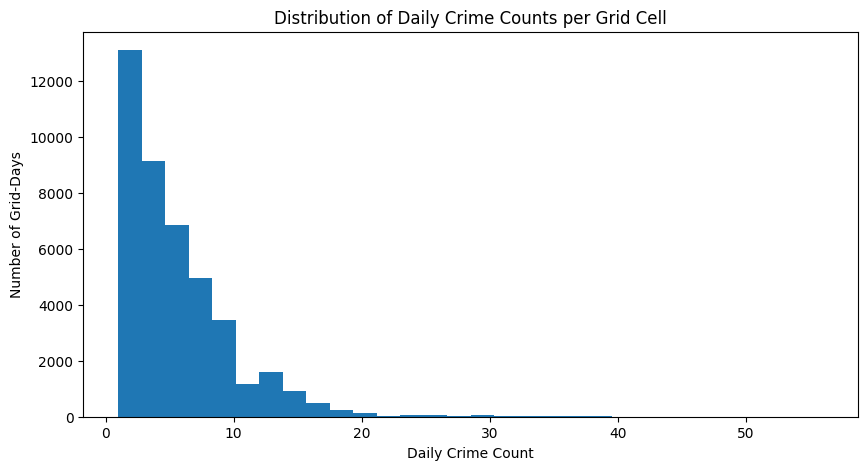

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    daily_grid_features["CRIME_COUNT"],
    bins=30
)

plt.xlabel("Daily Crime Count")
plt.ylabel("Number of Grid-Days")
plt.title("Distribution of Daily Crime Counts per Grid Cell")

plt.show()

# 6.6 — Z-score normalization of crime frequency

## Aggregate crime frequency for each grid cell

In [24]:
# Step 6.5.1 — Aggregate crime frequency for each grid cell

grid_crime_features = (
    daily_grid_features
    .groupby("GRID_ID")
    .agg(
        CRIME_FREQUENCY=("CRIME_COUNT", "sum"),
        MEAN_DAILY_CRIME=("CRIME_COUNT", "mean"),
        MAX_DAILY_CRIME=("CRIME_COUNT", "max"),
        ACTIVE_DAYS=("CRIME_COUNT", "count")
    )
    .reset_index()
)

print("Shape:", grid_crime_features.shape)

display(
    grid_crime_features.sort_values(
        "CRIME_FREQUENCY",
        ascending=False
    ).head(10)
)

Shape: (157, 5)


,GRID_ID,CRIME_FREQUENCY,MEAN_DAILY_CRIME,MAX_DAILY_CRIME,ACTIVE_DAYS
17,12_10,9549,26.233516,56,364
13,11_6,4868,13.336986,28,365
24,12_9,4586,12.564384,30,365
10,11_10,4467,12.238356,31,365
124,6_10,4464,12.263736,23,364
16,11_9,4044,11.079452,29,365
14,11_7,3967,10.868493,22,365
117,5_12,3960,10.849315,21,365
41,14_9,3810,10.467033,46,364
123,5_9,3651,10.002740,24,365


In [25]:
# Validate against grid_nodes.csv

check = grid_crime_features.merge(
    grid_nodes[["GRID_ID", "CRIME_COUNT"]],
    on="GRID_ID",
    how="left"
)

check["DIFFERENCE"] = (
    check["CRIME_FREQUENCY"] - check["CRIME_COUNT"]
)

print("Maximum difference:", check["DIFFERENCE"].abs().max())
print("Mismatched grids:", (check["DIFFERENCE"] != 0).sum())

Maximum difference: 0
Mismatched grids: 0


## Z-score normalization

In [26]:
# Step 6.5.2 — Z-score normalization of crime frequency

mean_crime = grid_crime_features["CRIME_FREQUENCY"].mean()
std_crime = grid_crime_features["CRIME_FREQUENCY"].std()

grid_crime_features["CRIME_FREQUENCY_Z"] = (
    grid_crime_features["CRIME_FREQUENCY"] - mean_crime
) / std_crime

print("Mean crime frequency:", mean_crime)
print("Standard deviation:", std_crime)

print("\nNormalized crime frequency statistics:")
display(
    grid_crime_features["CRIME_FREQUENCY_Z"].describe()
)

Mean crime frequency: 1456.0191082802548
Standard deviation: 1410.698978736035

Normalized crime frequency statistics:


count    1.570000e+02
mean    -6.788625e-17
std      1.000000e+00
min     -1.031417e+00
25%     -8.343517e-01
50%     -2.665481e-01
75%      6.521454e-01
max      5.736859e+00
Name: CRIME_FREQUENCY_Z, dtype: float64

In [27]:
# Highest and lowest normalized crime-frequency grids

print("Highest crime-frequency grids:")
display(
    grid_crime_features
    .sort_values("CRIME_FREQUENCY_Z", ascending=False)
    .head(10)
)

print("\nLowest crime-frequency grids:")
display(
    grid_crime_features
    .sort_values("CRIME_FREQUENCY_Z", ascending=True)
    .head(10)
)

Highest crime-frequency grids:


,GRID_ID,CRIME_FREQUENCY,MEAN_DAILY_CRIME,MAX_DAILY_CRIME,ACTIVE_DAYS,CRIME_FREQUENCY_Z
17,12_10,9549,26.233516,56,364,5.736859
13,11_6,4868,13.336986,28,365,2.418646
24,12_9,4586,12.564384,30,365,2.218745
10,11_10,4467,12.238356,31,365,2.134389
124,6_10,4464,12.263736,23,364,2.132263
16,11_9,4044,11.079452,29,365,1.834538
14,11_7,3967,10.868493,22,365,1.779955
117,5_12,3960,10.849315,21,365,1.774993
41,14_9,3810,10.467033,46,364,1.668663
123,5_9,3651,10.002740,24,365,1.555953



Lowest crime-frequency grids:


,GRID_ID,CRIME_FREQUENCY,MEAN_DAILY_CRIME,MAX_DAILY_CRIME,ACTIVE_DAYS,CRIME_FREQUENCY_Z
71,18_0,1,1.0,1,1,-1.031417
101,3_14,1,1.0,1,1,-1.031417
62,17_1,1,1.0,1,1,-1.031417
84,1_6,2,1.0,1,2,-1.030708
42,15_0,5,1.0,1,5,-1.028582
72,18_2,5,1.0,1,5,-1.028582
81,1_11,5,1.0,1,5,-1.028582
18,12_11,13,1.0,1,13,-1.022911
75,18_5,14,1.0,1,14,-1.022202
136,7_12,16,1.0,1,16,-1.020784


## Add spatial features to the grid-level data

In [28]:
# Step 6.5.3 — Create grid-level node features

node_features = grid_crime_features.merge(
    grid_nodes[
        [
            "GRID_ID",
            "GRID_ROW",
            "GRID_COL",
            "GRID_CENTER_LAT",
            "GRID_CENTER_LON"
        ]
    ],
    on="GRID_ID",
    how="left"
)

print("Node feature shape:", node_features.shape)

display(node_features.head())

Node feature shape: (157, 10)


,GRID_ID,CRIME_FREQUENCY,MEAN_DAILY_CRIME,MAX_DAILY_CRIME,ACTIVE_DAYS,CRIME_FREQUENCY_Z,GRID_ROW,GRID_COL,GRID_CENTER_LAT,GRID_CENTER_LON
0,0_10,595,2.073171,9,287,-0.610349,0,10,41.654305,-87.617586
1,0_11,559,2.010791,7,278,-0.635869,0,11,41.654444,-87.591166
2,0_12,121,1.234694,6,98,-0.946353,0,12,41.654577,-87.564745
3,0_13,451,1.879167,24,240,-0.712426,0,13,41.654704,-87.538324
4,0_9,218,1.453333,5,150,-0.877593,0,9,41.654160,-87.644006


In [29]:
# Validation

print("Number of nodes:", len(node_features))
print("Missing latitude:", node_features["GRID_CENTER_LAT"].isna().sum())
print("Missing longitude:", node_features["GRID_CENTER_LON"].isna().sum())
print("Duplicate GRID_IDs:", node_features["GRID_ID"].duplicated().sum())

Number of nodes: 157
Missing latitude: 0
Missing longitude: 0
Duplicate GRID_IDs: 0


## Add crime-type features to each grid node

In [30]:
# Step 6.5.4 — Aggregate crime types at grid level

grid_crime_types = (
    crime_features
    .groupby(["GRID_ID", "CRIME_TYPE"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

print("Shape:", grid_crime_types.shape)

display(grid_crime_types.head())

Shape: (157, 18)


CRIME_TYPE,GRID_ID,ASSAULT,BATTERY,BURGLARY,CRIMINAL DAMAGE,CRIMINAL SEXUAL ASSAULT,CRIMINAL TRESPASS,DECEPTIVE PRACTICE,MOTOR VEHICLE THEFT,NARCOTICS,OFFENSE INVOLVING CHILDREN,OTHER,OTHER OFFENSE,PUBLIC PEACE VIOLATION,ROBBERY,SEX OFFENSE,THEFT,WEAPONS VIOLATION
0,0_10,82,160,22,77,5,7,17,37,7,3,10,53,0,15,3,67,30
1,0_11,99,155,9,73,3,11,11,25,12,6,6,56,3,10,1,59,20
2,0_12,13,23,5,20,1,4,1,19,1,0,0,12,2,3,0,17,0
3,0_13,45,89,27,100,2,11,18,48,1,1,2,44,1,7,5,43,7
4,0_9,19,34,17,28,2,6,8,24,2,1,6,24,2,2,2,38,3


In [31]:
# Add crime-type features to node features

node_features = node_features.merge(
    grid_crime_types,
    on="GRID_ID",
    how="left"
)

print("New node feature shape:", node_features.shape)

display(node_features.head())

New node feature shape: (157, 27)


,GRID_ID,CRIME_FREQUENCY,MEAN_DAILY_CRIME,MAX_DAILY_CRIME,ACTIVE_DAYS,CRIME_FREQUENCY_Z,GRID_ROW,GRID_COL,GRID_CENTER_LAT,GRID_CENTER_LON,ASSAULT,BATTERY,BURGLARY,CRIMINAL DAMAGE,CRIMINAL SEXUAL ASSAULT,CRIMINAL TRESPASS,DECEPTIVE PRACTICE,MOTOR VEHICLE THEFT,NARCOTICS,OFFENSE INVOLVING CHILDREN,OTHER,OTHER OFFENSE,PUBLIC PEACE VIOLATION,ROBBERY,SEX OFFENSE,THEFT,WEAPONS VIOLATION
0,0_10,595,2.073171,9,287,-0.610349,0,10,41.654305,-87.617586,82,160,22,77,5,7,17,37,7,3,10,53,0,15,3,67,30
1,0_11,559,2.010791,7,278,-0.635869,0,11,41.654444,-87.591166,99,155,9,73,3,11,11,25,12,6,6,56,3,10,1,59,20
2,0_12,121,1.234694,6,98,-0.946353,0,12,41.654577,-87.564745,13,23,5,20,1,4,1,19,1,0,0,12,2,3,0,17,0
3,0_13,451,1.879167,24,240,-0.712426,0,13,41.654704,-87.538324,45,89,27,100,2,11,18,48,1,1,2,44,1,7,5,43,7
4,0_9,218,1.453333,5,150,-0.877593,0,9,41.654160,-87.644006,19,34,17,28,2,6,8,24,2,1,6,24,2,2,2,38,3


In [32]:
# Validate grid-level crime-type totals

crime_type_columns = [
    col for col in grid_crime_types.columns
    if col != "GRID_ID"
]

node_features["CRIME_TYPE_SUM"] = (
    node_features[crime_type_columns].sum(axis=1)
)

node_features["TYPE_COUNT_DIFFERENCE"] = (
    node_features["CRIME_FREQUENCY"]
    - node_features["CRIME_TYPE_SUM"]
)

print(
    "Maximum absolute difference:",
    node_features["TYPE_COUNT_DIFFERENCE"].abs().max()
)

print(
    "Number of mismatched grids:",
    (node_features["TYPE_COUNT_DIFFERENCE"] != 0).sum()
)

Maximum absolute difference: 0
Number of mismatched grids: 0


## Normalize latitude and longitude

In [33]:
# Step 6.5.5 — Normalize spatial coordinates to [0, 1]

lat_min = node_features["GRID_CENTER_LAT"].min()
lat_max = node_features["GRID_CENTER_LAT"].max()

lon_min = node_features["GRID_CENTER_LON"].min()
lon_max = node_features["GRID_CENTER_LON"].max()

node_features["LAT_NORM"] = (
    (node_features["GRID_CENTER_LAT"] - lat_min)
    / (lat_max - lat_min)
)

node_features["LON_NORM"] = (
    (node_features["GRID_CENTER_LON"] - lon_min)
    / (lon_max - lon_min)
)

print("Latitude normalized range:")
print(node_features["LAT_NORM"].min(), "to", node_features["LAT_NORM"].max())

print("\nLongitude normalized range:")
print(node_features["LON_NORM"].min(), "to", node_features["LON_NORM"].max())

Latitude normalized range:
0.0 to 1.0

Longitude normalized range:
0.0 to 1.0


In [34]:
# Validation

print("Latitude values outside [0,1]:",
      ((node_features["LAT_NORM"] < 0) |
       (node_features["LAT_NORM"] > 1)).sum())

print("Longitude values outside [0,1]:",
      ((node_features["LON_NORM"] < 0) |
       (node_features["LON_NORM"] > 1)).sum())

print("\nMissing normalized latitude:",
      node_features["LAT_NORM"].isna().sum())

print("Missing normalized longitude:",
      node_features["LON_NORM"].isna().sum())

Latitude values outside [0,1]: 0
Longitude values outside [0,1]: 0

Missing normalized latitude: 0
Missing normalized longitude: 0


In [35]:
display(
    node_features[
        [
            "GRID_ID",
            "GRID_CENTER_LAT",
            "GRID_CENTER_LON",
            "LAT_NORM",
            "LON_NORM",
            "CRIME_FREQUENCY",
            "CRIME_FREQUENCY_Z"
        ]
    ].head(10)
)

,GRID_ID,GRID_CENTER_LAT,GRID_CENTER_LON,LAT_NORM,LON_NORM,CRIME_FREQUENCY,CRIME_FREQUENCY_Z
0,0_10,41.654305,-87.617586,0.000385,0.718619,595,-0.610349
1,0_11,41.654444,-87.591166,0.000754,0.789173,559,-0.635869
2,0_12,41.654577,-87.564745,0.001108,0.859728,121,-0.946353
3,0_13,41.654704,-87.538324,0.001444,0.930283,451,-0.712426
4,0_9,41.654160,-87.644006,0.000000,0.648065,218,-0.877593
5,10_10,41.852449,-87.619488,0.526926,0.713539,2196,0.524549
6,10_6,41.851828,-87.725493,0.525277,0.430458,2877,1.007289
7,10_7,41.851992,-87.698993,0.525713,0.501227,2837,0.978934
8,10_8,41.852151,-87.672491,0.526134,0.571997,1629,0.122621
9,10_9,41.852303,-87.645990,0.526538,0.642768,1936,0.340243


## 6.7 — Build the final node feature matrix

## Inspect final node features

In [36]:
# Step 6.6.1 — Inspect final node features

print("Total columns:", len(node_features.columns))

print("\nColumns:")
for i, col in enumerate(node_features.columns, start=1):
    print(i, col)

Total columns: 31

Columns:
1 GRID_ID
2 CRIME_FREQUENCY
3 MEAN_DAILY_CRIME
4 MAX_DAILY_CRIME
5 ACTIVE_DAYS
6 CRIME_FREQUENCY_Z
7 GRID_ROW
8 GRID_COL
9 GRID_CENTER_LAT
10 GRID_CENTER_LON
11 ASSAULT
12 BATTERY
13 BURGLARY
14 CRIMINAL DAMAGE
15 CRIMINAL SEXUAL ASSAULT
16 CRIMINAL TRESPASS
17 DECEPTIVE PRACTICE
18 MOTOR VEHICLE THEFT
19 NARCOTICS
20 OFFENSE INVOLVING CHILDREN
21 OTHER
22 OTHER OFFENSE
23 PUBLIC PEACE VIOLATION
24 ROBBERY
25 SEX OFFENSE
26 THEFT
27 WEAPONS VIOLATION
28 CRIME_TYPE_SUM
29 TYPE_COUNT_DIFFERENCE
30 LAT_NORM
31 LON_NORM


In [37]:
# Check for missing values

print("Total missing values:",
      node_features.isna().sum().sum())

print("\nColumns with missing values:")
display(
    node_features.isna().sum()
    .loc[lambda x: x > 0]
)

Total missing values: 0

Columns with missing values:


Series([], dtype: int64)

In [38]:
# Check duplicated grid nodes

print(
    "Duplicate GRID_IDs:",
    node_features["GRID_ID"].duplicated().sum()
)

Duplicate GRID_IDs: 0


## Select final node features

In [39]:
# Step 6.6.1 — Select final node features

crime_type_columns = [
    "ASSAULT",
    "BATTERY",
    "BURGLARY",
    "CRIMINAL DAMAGE",
    "CRIMINAL SEXUAL ASSAULT",
    "CRIMINAL TRESPASS",
    "DECEPTIVE PRACTICE",
    "MOTOR VEHICLE THEFT",
    "NARCOTICS",
    "OFFENSE INVOLVING CHILDREN",
    "OTHER",
    "OTHER OFFENSE",
    "PUBLIC PEACE VIOLATION",
    "ROBBERY",
    "SEX OFFENSE",
    "THEFT",
    "WEAPONS VIOLATION"
]

feature_columns = [
    "LAT_NORM",
    "LON_NORM",
    "CRIME_FREQUENCY_Z",
    "MEAN_DAILY_CRIME",
    "MAX_DAILY_CRIME",
    "ACTIVE_DAYS"
] + crime_type_columns

X = node_features[feature_columns].copy()

print("Feature matrix shape:", X.shape)

print("\nNumber of features:", X.shape[1])

print("\nFeatures:")
for i, col in enumerate(X.columns, start=1):
    print(i, col)

Feature matrix shape: (157, 23)

Number of features: 23

Features:
1 LAT_NORM
2 LON_NORM
3 CRIME_FREQUENCY_Z
4 MEAN_DAILY_CRIME
5 MAX_DAILY_CRIME
6 ACTIVE_DAYS
7 ASSAULT
8 BATTERY
9 BURGLARY
10 CRIMINAL DAMAGE
11 CRIMINAL SEXUAL ASSAULT
12 CRIMINAL TRESPASS
13 DECEPTIVE PRACTICE
14 MOTOR VEHICLE THEFT
15 NARCOTICS
16 OFFENSE INVOLVING CHILDREN
17 OTHER
18 OTHER OFFENSE
19 PUBLIC PEACE VIOLATION
20 ROBBERY
21 SEX OFFENSE
22 THEFT
23 WEAPONS VIOLATION


In [40]:
# Validate final feature matrix

print("Number of nodes:", X.shape[0])
print("Number of features:", X.shape[1])
print("Missing values:", X.isna().sum().sum())
print("Infinite values:", np.isinf(X.to_numpy()).sum())

Number of nodes: 157
Number of features: 23
Missing values: 0
Infinite values: 0


# 6.7 — Create the GCN target

## Find dominant crime type for each grid

In [41]:
# Step 6.7.1 — Determine dominant crime type for each grid

crime_type_columns = [
    "ASSAULT",
    "BATTERY",
    "BURGLARY",
    "CRIMINAL DAMAGE",
    "CRIMINAL SEXUAL ASSAULT",
    "CRIMINAL TRESPASS",
    "DECEPTIVE PRACTICE",
    "MOTOR VEHICLE THEFT",
    "NARCOTICS",
    "OFFENSE INVOLVING CHILDREN",
    "OTHER",
    "OTHER OFFENSE",
    "PUBLIC PEACE VIOLATION",
    "ROBBERY",
    "SEX OFFENSE",
    "THEFT",
    "WEAPONS VIOLATION"
]

node_features["TARGET_CRIME_TYPE"] = (
    node_features[crime_type_columns]
    .idxmax(axis=1)
)

print("Number of target classes:",
      node_features["TARGET_CRIME_TYPE"].nunique())

print("\nTarget distribution:")
display(
    node_features["TARGET_CRIME_TYPE"]
    .value_counts()
)

Number of target classes: 7

Target distribution:


TARGET_CRIME_TYPE
BATTERY                76
THEFT                  71
DECEPTIVE PRACTICE      3
CRIMINAL DAMAGE         2
MOTOR VEHICLE THEFT     2
ASSAULT                 2
SEX OFFENSE             1
Name: count, dtype: int64

## Inspect the targets

In [42]:
# Show grid, crime frequency and target

display(
    node_features[
        [
            "GRID_ID",
            "CRIME_FREQUENCY",
            "CRIME_FREQUENCY_Z",
            "TARGET_CRIME_TYPE"
        ]
    ]
    .sort_values("CRIME_FREQUENCY", ascending=False)
    .head(20)
)

,GRID_ID,CRIME_FREQUENCY,CRIME_FREQUENCY_Z,TARGET_CRIME_TYPE
17,12_10,9549,5.736859,THEFT
13,11_6,4868,2.418646,BATTERY
24,12_9,4586,2.218745,THEFT
10,11_10,4467,2.134389,THEFT
124,6_10,4464,2.132263,BATTERY
16,11_9,4044,1.834538,THEFT
14,11_7,3967,1.779955,BATTERY
117,5_12,3960,1.774993,BATTERY
41,14_9,3810,1.668663,THEFT
123,5_9,3651,1.555953,BATTERY


# 6.8 — Encode TARGET_CRIME_TYPE

In [43]:
# Step 6.8.1 — Encode target crime classes

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

node_features["TARGET"] = label_encoder.fit_transform(
    node_features["TARGET_CRIME_TYPE"]
)

print("Number of classes:", len(label_encoder.classes_))

print("\nClass mapping:")
for i, crime_type in enumerate(label_encoder.classes_):
    print(f"{i}: {crime_type}")

Number of classes: 7

Class mapping:
0: ASSAULT
1: BATTERY
2: CRIMINAL DAMAGE
3: DECEPTIVE PRACTICE
4: MOTOR VEHICLE THEFT
5: SEX OFFENSE
6: THEFT


## Check the encoded target

In [44]:
# Check target distribution

target_distribution = (
    node_features["TARGET"]
    .value_counts()
    .sort_index()
    .rename_axis("TARGET")
    .reset_index(name="GRID_COUNT")
)

target_distribution["CRIME_TYPE"] = (
    target_distribution["TARGET"]
    .map(dict(enumerate(label_encoder.classes_)))
)

display(
    target_distribution[
        ["TARGET", "CRIME_TYPE", "GRID_COUNT"]
    ]
)

,TARGET,CRIME_TYPE,GRID_COUNT
0,0,ASSAULT,2
1,1,BATTERY,76
2,2,CRIMINAL DAMAGE,2
3,3,DECEPTIVE PRACTICE,3
4,4,MOTOR VEHICLE THEFT,2
5,5,SEX OFFENSE,1
6,6,THEFT,71


In [45]:
print("Total grid nodes:", len(node_features))
print("Missing targets:", node_features["TARGET"].isna().sum())
print("Unique targets:", node_features["TARGET"].nunique())
print("Minimum target:", node_features["TARGET"].min())
print("Maximum target:", node_features["TARGET"].max())

Total grid nodes: 157
Missing targets: 0
Unique targets: 7
Minimum target: 0
Maximum target: 6


In [46]:
# Check which crime types are actually dominant across grid cells

target_distribution = (
    node_features["TARGET_CRIME_TYPE"]
    .value_counts()
    .reset_index()
)

target_distribution.columns = ["CRIME_TYPE", "GRID_COUNT"]

display(target_distribution)

,CRIME_TYPE,GRID_COUNT
0,BATTERY,76
1,THEFT,71
2,DECEPTIVE PRACTICE,3
3,CRIMINAL DAMAGE,2
4,MOTOR VEHICLE THEFT,2
5,ASSAULT,2
6,SEX OFFENSE,1


In [47]:
# Show all 17 possible crime classes
print("All crime classes:")
for crime_type in label_encoder.classes_:
    print("-", crime_type)

print("\nDominant crime classes:")
for crime_type in sorted(node_features["TARGET_CRIME_TYPE"].unique()):
    print("-", crime_type)

All crime classes:
- ASSAULT
- BATTERY
- CRIMINAL DAMAGE
- DECEPTIVE PRACTICE
- MOTOR VEHICLE THEFT
- SEX OFFENSE
- THEFT

Dominant crime classes:
- ASSAULT
- BATTERY
- CRIMINAL DAMAGE
- DECEPTIVE PRACTICE
- MOTOR VEHICLE THEFT
- SEX OFFENSE
- THEFT


# 6.9 — Create X and y

In [48]:
# Step 6.9.1 — Final node features and target

X = node_features[feature_columns].copy()

y = node_features["TARGET"].values

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (157, 23)
y shape: (157,)


# 7 — Prepare the Graph

## Create adjacency matrix

In [49]:
# Step 7.1 — Build graph adjacency matrix

from sklearn.metrics.pairwise import haversine_distances
import numpy as np

# Grid center coordinates
coords = node_features[
    ["GRID_CENTER_LAT", "GRID_CENTER_LON"]
].to_numpy()

# Convert degrees to radians
coords_rad = np.radians(coords)

# Calculate pairwise Haversine distances
distance_matrix = (
    haversine_distances(coords_rad) * 6371.0
)

print("Distance matrix shape:", distance_matrix.shape)

Distance matrix shape: (157, 157)


## Connect neighboring grid cells

In [50]:
# Step 7.2 — Create weighted adjacency matrix

DISTANCE_THRESHOLD = 3.0

A = np.zeros_like(distance_matrix)

# Connect nodes within 3 km
mask = (
    (distance_matrix > 0) &
    (distance_matrix <= DISTANCE_THRESHOLD)
)

# Inverse-distance weighting
A[mask] = 1 / distance_matrix[mask]

print("Adjacency matrix shape:", A.shape)
print("Non-zero connections:", np.count_nonzero(A))

Adjacency matrix shape: (157, 157)
Non-zero connections: 544


In [51]:
# Step 7.3 — Validate adjacency matrix

print("Symmetric:", np.allclose(A, A.T))
print("Self-connections:", np.count_nonzero(np.diag(A)))
print("Minimum non-zero weight:", A[A > 0].min())
print("Maximum weight:", A[A > 0].max())

Symmetric: True
Self-connections: 0
Minimum non-zero weight: 0.45385127726489266
Maximum weight: 0.4555847421826671


## Check node degrees

In [52]:
# Step 7.4 — Calculate node degrees

node_degree = (A > 0).sum(axis=1)

print("Number of nodes:", len(node_degree))
print("Average degree:", node_degree.mean())
print("Minimum degree:", node_degree.min())
print("Maximum degree:", node_degree.max())
print("Isolated nodes:", (node_degree == 0).sum())

Number of nodes: 157
Average degree: 3.464968152866242
Minimum degree: 1
Maximum degree: 4
Isolated nodes: 0


# 8 — Split the graph nodes

## Create train/validation/test masks

In [53]:
# Step 8.1 — Create reproducible train/validation/test split

import numpy as np

np.random.seed(42)

node_indices = np.arange(len(node_features))
y = node_features["TARGET"].values

# Find the single SEX OFFENSE node
sex_offense_class = label_encoder.transform(["SEX OFFENSE"])[0]
sex_offense_idx = np.where(y == sex_offense_class)[0]

print("SEX OFFENSE class:", sex_offense_class)
print("SEX OFFENSE node index:", sex_offense_idx)

SEX OFFENSE class: 5
SEX OFFENSE node index: [101]


## Randomly split the remaining nodes

In [54]:
# Remove the single SEX OFFENSE node from the pool
remaining_idx = node_indices[
    ~np.isin(node_indices, sex_offense_idx)
]

# Shuffle remaining nodes
np.random.shuffle(remaining_idx)

# 70% train, 15% validation, 15% test
n_remaining = len(remaining_idx)

n_train = int(0.70 * n_remaining)
n_val = int(0.15 * n_remaining)

train_idx = remaining_idx[:n_train]
val_idx = remaining_idx[n_train:n_train + n_val]
test_idx = remaining_idx[n_train + n_val:]

# Force SEX OFFENSE node into training
train_idx = np.concatenate([train_idx, sex_offense_idx])

print("Total nodes:", len(node_indices))
print("Training nodes:", len(train_idx))
print("Validation nodes:", len(val_idx))
print("Testing nodes:", len(test_idx))

Total nodes: 157
Training nodes: 110
Validation nodes: 23
Testing nodes: 24


## Create masks

In [55]:
# Create boolean masks

train_mask = np.zeros(len(node_features), dtype=bool)
val_mask = np.zeros(len(node_features), dtype=bool)
test_mask = np.zeros(len(node_features), dtype=bool)

train_mask[train_idx] = True
val_mask[val_idx] = True
test_mask[test_idx] = True

print("Train mask:", train_mask.sum())
print("Validation mask:", val_mask.sum())
print("Test mask:", test_mask.sum())

Train mask: 110
Validation mask: 23
Test mask: 24


## Check distributions

In [56]:
# Check class distribution in each split

class_names = label_encoder.classes_

def show_split_distribution(indices, split_name):
    counts = (
        pd.Series(y[indices])
        .value_counts()
        .sort_index()
    )

    result = pd.DataFrame({
        "TARGET": counts.index,
        "CRIME_TYPE": [
            class_names[i] for i in counts.index
        ],
        "GRID_COUNT": counts.values
    })

    result["PERCENT"] = (
        result["GRID_COUNT"] / len(indices) * 100
    ).round(2)

    print(f"\n{split_name}")
    display(result)


show_split_distribution(train_idx, "TRAIN")
show_split_distribution(val_idx, "VALIDATION")
show_split_distribution(test_idx, "TEST")


TRAIN


,TARGET,CRIME_TYPE,GRID_COUNT,PERCENT
0,0,ASSAULT,2,1.82
1,1,BATTERY,50,45.45
2,2,CRIMINAL DAMAGE,1,0.91
3,3,DECEPTIVE PRACTICE,2,1.82
4,4,MOTOR VEHICLE THEFT,1,0.91
5,5,SEX OFFENSE,1,0.91
6,6,THEFT,53,48.18



VALIDATION


,TARGET,CRIME_TYPE,GRID_COUNT,PERCENT
0,1,BATTERY,11,47.83
1,2,CRIMINAL DAMAGE,1,4.35
2,3,DECEPTIVE PRACTICE,1,4.35
3,6,THEFT,10,43.48



TEST


,TARGET,CRIME_TYPE,GRID_COUNT,PERCENT
0,1,BATTERY,15,62.50
1,4,MOTOR VEHICLE THEFT,1,4.17
2,6,THEFT,8,33.33


# 9 — Prepare the GCN inputs

## Install/check PyTorch

In [57]:
import torch

print("PyTorch version:", torch.__version__)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")

PyTorch version: 2.6.0+cpu
Device: cpu


## Convert X and y to tensors

In [58]:
# Step 9.2 — Convert node features and labels to PyTorch tensors

import torch

X_np = X.to_numpy(dtype=np.float32)
y_np = y.astype(np.int64)

X_tensor = torch.tensor(X_np, dtype=torch.float32)
y_tensor = torch.tensor(y_np, dtype=torch.long)

train_mask_tensor = torch.tensor(train_mask, dtype=torch.bool)
val_mask_tensor = torch.tensor(val_mask, dtype=torch.bool)
test_mask_tensor = torch.tensor(test_mask, dtype=torch.bool)

print("X tensor shape:", X_tensor.shape)
print("y tensor shape:", y_tensor.shape)

print("Train mask shape:", train_mask_tensor.shape)
print("Validation mask shape:", val_mask_tensor.shape)
print("Test mask shape:", test_mask_tensor.shape)

X tensor shape: torch.Size([157, 23])
y tensor shape: torch.Size([157])
Train mask shape: torch.Size([157])
Validation mask shape: torch.Size([157])
Test mask shape: torch.Size([157])


## Convert adjacency matrix

In [59]:
# Step 9.3 — Convert adjacency matrix to edge index

edge_source, edge_target = np.nonzero(A)

edge_index = torch.tensor(
    np.vstack([edge_source, edge_target]),
    dtype=torch.long
)

print("Edge index shape:", edge_index.shape)
print("Number of directed edges:", edge_index.shape[1])

Edge index shape: torch.Size([2, 544])
Number of directed edges: 544


## Create the complete graph data object

In [60]:
try:
    import torch_geometric
    print("PyTorch Geometric version:", torch_geometric.__version__)
except ImportError:
    print("PyTorch Geometric is NOT installed.")

PyTorch Geometric version: 2.8.0.post1


In [61]:
# pip install torch-geometric

## Test PyG

In [62]:
from torch_geometric.data import Data

graph_data = Data(
    x=X_tensor,
    edge_index=edge_index,
    y=y_tensor,
    train_mask=train_mask_tensor,
    val_mask=val_mask_tensor,
    test_mask=test_mask_tensor
)

print(graph_data)

Data(x=[157, 23], edge_index=[2, 544], y=[157], train_mask=[157], val_mask=[157], test_mask=[157])


In [63]:
print("Nodes:", graph_data.num_nodes)
print("Edges:", graph_data.num_edges)
print("Features per node:", graph_data.num_node_features)
print("Classes:", len(label_encoder.classes_))

Nodes: 157
Edges: 544
Features per node: 23
Classes: 7


# 11 — Build the GCN

## Import PyG layers

In [64]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.nn import GCNConv

## Define the GCN

In [65]:
# Step 11.2 — Two-layer GCN

class GCN(nn.Module):

    def __init__(
        self,
        input_features,
        hidden_features,
        output_classes,
        dropout=0.5
    ):
        super().__init__()

        self.conv1 = GCNConv(
            input_features,
            hidden_features
        )

        self.conv2 = GCNConv(
            hidden_features,
            output_classes
        )

        self.dropout = dropout

    def forward(self, x, edge_index):

        # First GCN layer
        x = self.conv1(x, edge_index)

        # ReLU activation
        x = F.relu(x)

        # Dropout
        x = F.dropout(
            x,
            p=self.dropout,
            training=self.training
        )

        # Second GCN layer
        x = self.conv2(x, edge_index)

        return x

## Create the model

In [66]:
# Step 11.3 — Initialize GCN

INPUT_FEATURES = X_tensor.shape[1]
HIDDEN_FEATURES = 128
OUTPUT_CLASSES = len(label_encoder.classes_)
DROPOUT = 0.5

model = GCN(
    input_features=INPUT_FEATURES,
    hidden_features=HIDDEN_FEATURES,
    output_classes=OUTPUT_CLASSES,
    dropout=DROPOUT
)

print(model)

GCN(
  (conv1): GCNConv(23, 128)
  (conv2): GCNConv(128, 7)
)


## Check the number of parameters

In [67]:
# Count trainable parameters

total_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", total_parameters)

Trainable parameters: 3975


## Move graph and model to CPU

In [68]:
device = torch.device("cpu")

model = model.to(device)
graph_data = graph_data.to(device)

print("Model device:", device)

Model device: cpu


# 12 — Handle class imbalance

## Calculate training class weights

In [69]:
# Step 12.1 — Calculate class weights using training data only

from sklearn.utils.class_weight import compute_class_weight

train_labels = y[train_idx]

classes = np.arange(OUTPUT_CLASSES)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_labels
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print("Class weights:")
for i, weight in enumerate(class_weights):
    print(
        f"{i}: {label_encoder.classes_[i]:25s} "
        f"{weight.item():.4f}"
    )

Class weights:
0: ASSAULT                   7.8571
1: BATTERY                   0.3143
2: CRIMINAL DAMAGE           15.7143
3: DECEPTIVE PRACTICE        7.8571
4: MOTOR VEHICLE THEFT       15.7143
5: SEX OFFENSE               15.7143
6: THEFT                     0.2965


## Create the loss function

In [70]:
# Step 12.2 — Weighted Cross Entropy Loss

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

print(criterion)

CrossEntropyLoss()


## Set optimizer

In [71]:
# Step 13 — Adam optimizer

LEARNING_RATE = 0.01
WEIGHT_DECAY = 5e-4

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)

Learning rate: 0.01
Weight decay: 0.0005


## Test one forward pass

In [72]:
# Step 14 — Forward pass test

model.eval()

with torch.no_grad():
    output = model(
        graph_data.x,
        graph_data.edge_index
    )

print("Output shape:", output.shape)

Output shape: torch.Size([157, 7])


In [73]:
print("First node output:")
print(output[0])

First node output:
tensor([ 23.8328,  37.1972, -38.8453,  34.5969,  71.9472, -52.9894, -44.3427])


# 15 — Train the GCN

## Create the training loop

In [74]:
# Step 15.1 — GCN training

from sklearn.metrics import accuracy_score, f1_score

EPOCHS = 200

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

train_f1_scores = []
val_f1_scores = []

best_val_f1 = -1
best_model_state = None
best_epoch = 0

for epoch in range(1, EPOCHS + 1):

    # -------------------------
    # Training
    # -------------------------
    model.train()

    optimizer.zero_grad()

    output = model(
        graph_data.x,
        graph_data.edge_index
    )

    train_loss = criterion(
        output[graph_data.train_mask],
        graph_data.y[graph_data.train_mask]
    )

    train_loss.backward()
    optimizer.step()

    # -------------------------
    # Evaluation
    # -------------------------
    model.eval()

    with torch.no_grad():

        output = model(
            graph_data.x,
            graph_data.edge_index
        )

        # Training
        train_pred = output[
            graph_data.train_mask
        ].argmax(dim=1)

        train_true = graph_data.y[
            graph_data.train_mask
        ]

        # Validation
        val_pred = output[
            graph_data.val_mask
        ].argmax(dim=1)

        val_true = graph_data.y[
            graph_data.val_mask
        ]

        train_loss_value = train_loss.item()

        val_loss = criterion(
            output[graph_data.val_mask],
            graph_data.y[graph_data.val_mask]
        )

        train_accuracy = accuracy_score(
            train_true.cpu().numpy(),
            train_pred.cpu().numpy()
        )

        val_accuracy = accuracy_score(
            val_true.cpu().numpy(),
            val_pred.cpu().numpy()
        )

        train_f1 = f1_score(
            train_true.cpu().numpy(),
            train_pred.cpu().numpy(),
            average="macro",
            zero_division=0
        )

        val_f1 = f1_score(
            val_true.cpu().numpy(),
            val_pred.cpu().numpy(),
            average="macro",
            zero_division=0
        )

    # Store metrics
    train_losses.append(train_loss_value)
    val_losses.append(val_loss.item())

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    train_f1_scores.append(train_f1)
    val_f1_scores.append(val_f1)

    # Save best model
    if val_f1 > best_val_f1:

        best_val_f1 = val_f1
        best_epoch = epoch

        best_model_state = {
            key: value.cpu().clone()
            for key, value in model.state_dict().items()
        }

    # Print progress
    if epoch == 1 or epoch % 10 == 0:

        print(
            f"Epoch {epoch:03d} | "
            f"Train Loss: {train_loss_value:.4f} | "
            f"Val Loss: {val_loss.item():.4f} | "
            f"Train Acc: {train_accuracy:.4f} | "
            f"Val Acc: {val_accuracy:.4f} | "
            f"Train F1: {train_f1:.4f} | "
            f"Val F1: {val_f1:.4f}"
        )

print("\nTraining completed.")
print("Best epoch:", best_epoch)
print("Best validation Macro F1:", round(best_val_f1, 4))

Epoch 001 | Train Loss: 65.4708 | Val Loss: 38.1779 | Train Acc: 0.4545 | Val Acc: 0.4783 | Train F1: 0.0893 | Val F1: 0.1618
Epoch 010 | Train Loss: 16.0777 | Val Loss: 3.6912 | Train Acc: 0.5364 | Val Acc: 0.5217 | Train F1: 0.1933 | Val F1: 0.2583


Epoch 020 | Train Loss: 5.9031 | Val Loss: 1.7584 | Train Acc: 0.5545 | Val Acc: 0.5652 | Train F1: 0.2203 | Val F1: 0.3475
Epoch 030 | Train Loss: 3.2732 | Val Loss: 1.4294 | Train Acc: 0.6091 | Val Acc: 0.6087 | Train F1: 0.4056 | Val F1: 0.2595
Epoch 040 | Train Loss: 2.2412 | Val Loss: 2.0760 | Train Acc: 0.5545 | Val Acc: 0.4783 | Train F1: 0.4365 | Val F1: 0.1686
Epoch 050 | Train Loss: 0.8709 | Val Loss: 0.9214 | Train Acc: 0.6909 | Val Acc: 0.6087 | Train F1: 0.5011 | Val F1: 0.3194
Epoch 060 | Train Loss: 0.7222 | Val Loss: 1.0829 | Train Acc: 0.6545 | Val Acc: 0.5652 | Train F1: 0.5743 | Val F1: 0.3175
Epoch 070 | Train Loss: 0.8149 | Val Loss: 1.4138 | Train Acc: 0.7182 | Val Acc: 0.5652 | Train F1: 0.5738 | Val F1: 0.3283
Epoch 080 | Train Loss: 0.5694 | Val Loss: 0.6767 | Train Acc: 0.7000 | Val Acc: 0.6522 | Train F1: 0.5611 | Val F1: 0.3373
Epoch 090 | Train Loss: 0.5368 | Val Loss: 0.9138 | Train Acc: 0.6364 | Val Acc: 0.6522 | Train F1: 0.4990 | Val F1: 0.3626
Epoch 10

## Restore the best model

In [75]:
# Step 15.2 — Restore best validation model

model.load_state_dict(best_model_state)

print("Restored best model from epoch:", best_epoch)
print("Best validation Macro F1:", round(best_val_f1, 4))

Restored best model from epoch: 23
Best validation Macro F1: 0.5625


## Plot training curves

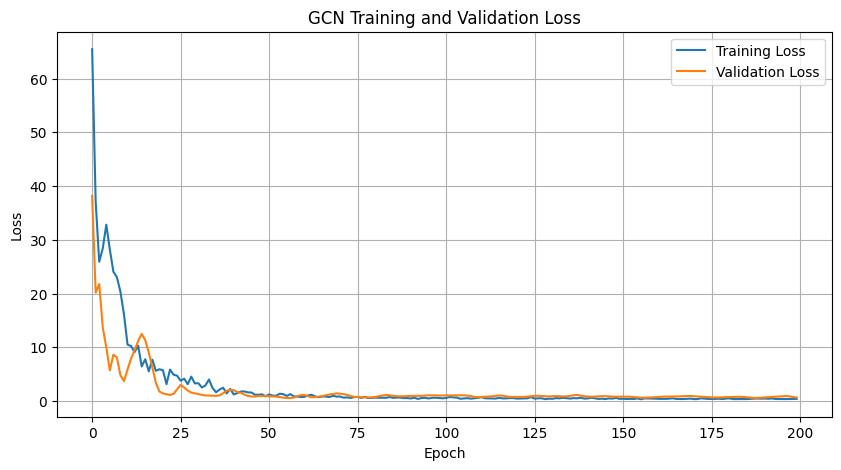

In [76]:
# Step 15.3 — Plot loss curves

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    train_losses,
    label="Training Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GCN Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

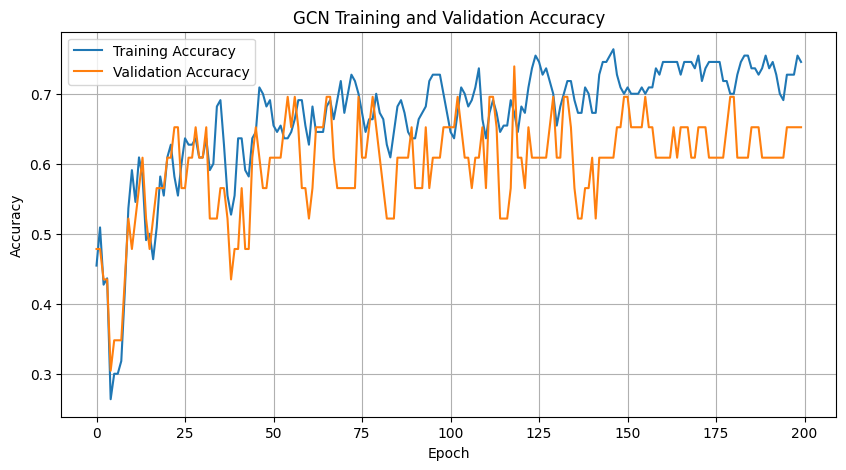

In [77]:
# Step 15.4 — Plot accuracy curves

plt.figure(figsize=(10, 5))

plt.plot(
    train_accuracies,
    label="Training Accuracy"
)

plt.plot(
    val_accuracies,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("GCN Training and Validation Accuracy")

plt.legend()
plt.grid(True)
plt.show()

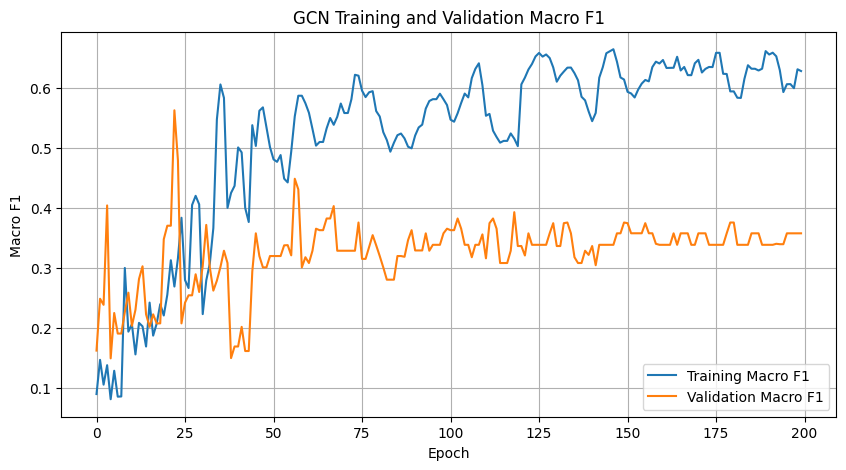

In [78]:
# Step 15.5 — Plot Macro F1

plt.figure(figsize=(10, 5))

plt.plot(
    train_f1_scores,
    label="Training Macro F1"
)

plt.plot(
    val_f1_scores,
    label="Validation Macro F1"
)

plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.title("GCN Training and Validation Macro F1")

plt.legend()
plt.grid(True)
plt.show()

# 16 — Final GCN Test Evaluation

## Generate test predictions

In [79]:
# Step 16.1 — Generate predictions on the test set

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

model.eval()

with torch.no_grad():
    output = model(
        graph_data.x,
        graph_data.edge_index
    )

test_logits = output[graph_data.test_mask]

test_predictions = test_logits.argmax(dim=1)

test_true = graph_data.y[graph_data.test_mask]

print("Test nodes:", len(test_true))
print("Predictions:", len(test_predictions))

Test nodes: 24
Predictions: 24


## Calculate overall metrics

In [80]:
# Step 16.2 — Calculate test metrics

y_test_true = test_true.cpu().numpy()
y_test_pred = test_predictions.cpu().numpy()

test_accuracy = accuracy_score(
    y_test_true,
    y_test_pred
)

test_precision_macro = precision_score(
    y_test_true,
    y_test_pred,
    average="macro",
    zero_division=0
)

test_recall_macro = recall_score(
    y_test_true,
    y_test_pred,
    average="macro",
    zero_division=0
)

test_f1_macro = f1_score(
    y_test_true,
    y_test_pred,
    average="macro",
    zero_division=0
)

test_f1_weighted = f1_score(
    y_test_true,
    y_test_pred,
    average="weighted",
    zero_division=0
)

print("GCN Test Results")
print("=" * 40)
print(f"Accuracy:          {test_accuracy:.4f}")
print(f"Macro Precision:   {test_precision_macro:.4f}")
print(f"Macro Recall:      {test_recall_macro:.4f}")
print(f"Macro F1:          {test_f1_macro:.4f}")
print(f"Weighted F1:       {test_f1_weighted:.4f}")

GCN Test Results
Accuracy:          0.6250
Macro Precision:   0.3292
Macro Recall:      0.2467
Macro F1:          0.2802
Weighted F1:       0.6962


## Classification report

In [81]:
# Step 16.3 — Detailed classification report

present_classes = np.unique(
    np.concatenate([y_test_true, y_test_pred])
)

print(
    classification_report(
        y_test_true,
        y_test_pred,
        labels=present_classes,
        target_names=[
            label_encoder.classes_[i]
            for i in present_classes
        ],
        zero_division=0
    )
)

                     precision    recall  f1-score   support

            BATTERY       0.85      0.73      0.79        15
    CRIMINAL DAMAGE       0.00      0.00      0.00         0
 DECEPTIVE PRACTICE       0.00      0.00      0.00         0
MOTOR VEHICLE THEFT       0.00      0.00      0.00         1
              THEFT       0.80      0.50      0.62         8

           accuracy                           0.62        24
          macro avg       0.33      0.25      0.28        24
       weighted avg       0.80      0.62      0.70        24



# Confusion matrix

In [82]:
# Step 16.4 — Confusion matrix

cm = confusion_matrix(
    y_test_true,
    y_test_pred,
    labels=present_classes
)

cm_df = pd.DataFrame(
    cm,
    index=[
        label_encoder.classes_[i]
        for i in present_classes
    ],
    columns=[
        label_encoder.classes_[i]
        for i in present_classes
    ]
)

print("Confusion Matrix:")
display(cm_df)

Confusion Matrix:


,BATTERY,CRIMINAL DAMAGE,DECEPTIVE PRACTICE,MOTOR VEHICLE THEFT,THEFT
BATTERY,11,1,2,0,1
CRIMINAL DAMAGE,0,0,0,0,0
DECEPTIVE PRACTICE,0,0,0,0,0
MOTOR VEHICLE THEFT,0,0,1,0,0
THEFT,2,0,2,0,4


## Visualize the confusion matrix

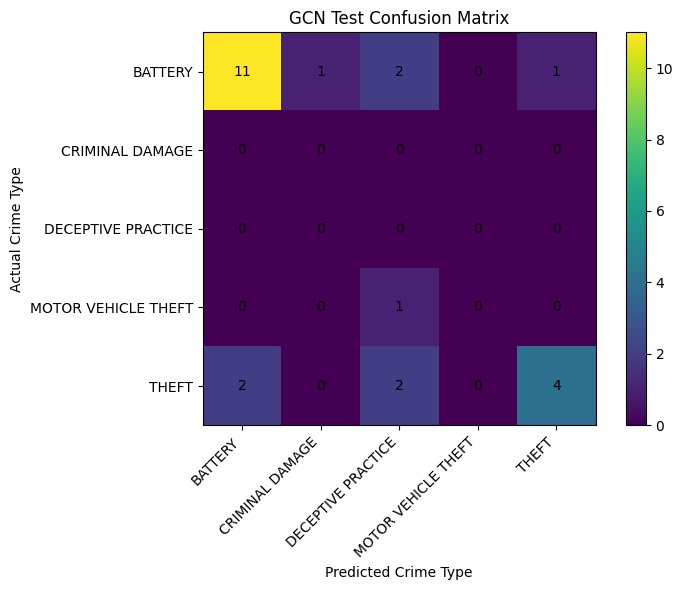

In [83]:
# Step 16.5 — Plot confusion matrix

plt.figure(figsize=(8, 6))

plt.imshow(cm)

plt.xticks(
    range(len(present_classes)),
    [
        label_encoder.classes_[i]
        for i in present_classes
    ],
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(present_classes)),
    [
        label_encoder.classes_[i]
        for i in present_classes
    ]
)

plt.xlabel("Predicted Crime Type")
plt.ylabel("Actual Crime Type")
plt.title("GCN Test Confusion Matrix")

plt.colorbar()

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

In [84]:
# Step 16.1 — Final GCN test evaluation

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

model.eval()

with torch.no_grad():
    output = model(
        graph_data.x,
        graph_data.edge_index
    )

test_pred = output[graph_data.test_mask].argmax(dim=1)
test_true = graph_data.y[graph_data.test_mask]

y_test_true = test_true.cpu().numpy()
y_test_pred = test_pred.cpu().numpy()

gcn_accuracy = accuracy_score(
    y_test_true,
    y_test_pred
)

gcn_precision = precision_score(
    y_test_true,
    y_test_pred,
    average="macro",
    zero_division=0
)

gcn_recall = recall_score(
    y_test_true,
    y_test_pred,
    average="macro",
    zero_division=0
)

gcn_macro_f1 = f1_score(
    y_test_true,
    y_test_pred,
    average="macro",
    zero_division=0
)

gcn_weighted_f1 = f1_score(
    y_test_true,
    y_test_pred,
    average="weighted",
    zero_division=0
)

print("GCN TEST RESULTS")
print("=" * 40)
print(f"Accuracy:        {gcn_accuracy:.4f}")
print(f"Macro Precision: {gcn_precision:.4f}")
print(f"Macro Recall:    {gcn_recall:.4f}")
print(f"Macro F1:        {gcn_macro_f1:.4f}")
print(f"Weighted F1:     {gcn_weighted_f1:.4f}")

GCN TEST RESULTS
Accuracy:        0.6250
Macro Precision: 0.3292
Macro Recall:    0.2467
Macro F1:        0.2802
Weighted F1:     0.6962


In [85]:
# Step 16.2 — Classification report

present_classes = np.unique(
    np.concatenate([y_test_true, y_test_pred])
)

print(
    classification_report(
        y_test_true,
        y_test_pred,
        labels=present_classes,
        target_names=[
            label_encoder.classes_[i]
            for i in present_classes
        ],
        zero_division=0
    )
)

                     precision    recall  f1-score   support

            BATTERY       0.85      0.73      0.79        15
    CRIMINAL DAMAGE       0.00      0.00      0.00         0
 DECEPTIVE PRACTICE       0.00      0.00      0.00         0
MOTOR VEHICLE THEFT       0.00      0.00      0.00         1
              THEFT       0.80      0.50      0.62         8

           accuracy                           0.62        24
          macro avg       0.33      0.25      0.28        24
       weighted avg       0.80      0.62      0.70        24



In [86]:
# Step 16.3 — Confusion matrix

cm = confusion_matrix(
    y_test_true,
    y_test_pred,
    labels=present_classes
)

cm_df = pd.DataFrame(
    cm,
    index=[
        label_encoder.classes_[i]
        for i in present_classes
    ],
    columns=[
        label_encoder.classes_[i]
        for i in present_classes
    ]
)

display(cm_df)

,BATTERY,CRIMINAL DAMAGE,DECEPTIVE PRACTICE,MOTOR VEHICLE THEFT,THEFT
BATTERY,11,1,2,0,1
CRIMINAL DAMAGE,0,0,0,0,0
DECEPTIVE PRACTICE,0,0,0,0,0
MOTOR VEHICLE THEFT,0,0,1,0,0
THEFT,2,0,2,0,4


In [87]:
# Step 16.4 — Store GCN results

results = pd.DataFrame([
    {
        "Model": "GCN",
        "Accuracy": gcn_accuracy,
        "Macro_Precision": gcn_precision,
        "Macro_Recall": gcn_recall,
        "Macro_F1": gcn_macro_f1,
        "Weighted_F1": gcn_weighted_f1
    }
])

display(results)

,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1
0,GCN,0.625,0.329231,0.246667,0.28022,0.6962


# 17 — SVM Baseline

## Prepare SVM data

In [88]:
# Step 17.1 — Prepare SVM features

from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

svm_features = [
    "LAT_NORM",
    "LON_NORM",
    "CRIME_FREQUENCY_Z"
]

X_svm = node_features[svm_features].copy()
y_svm = node_features["TARGET"].values

print("SVM features:")
print(svm_features)

print("\nX shape:", X_svm.shape)
print("y shape:", y_svm.shape)

SVM features:
['LAT_NORM', 'LON_NORM', 'CRIME_FREQUENCY_Z']

X shape: (157, 3)
y shape: (157,)


## Scale the SVM features

In [89]:
# Step 17.2 — Standardize SVM features

scaler_svm = StandardScaler()

X_svm_train = scaler_svm.fit_transform(
    X_svm.iloc[train_idx]
)

X_svm_val = scaler_svm.transform(
    X_svm.iloc[val_idx]
)

X_svm_test = scaler_svm.transform(
    X_svm.iloc[test_idx]
)

y_svm_train = y_svm[train_idx]
y_svm_val = y_svm[val_idx]
y_svm_test = y_svm[test_idx]

print("Training:", X_svm_train.shape)
print("Validation:", X_svm_val.shape)
print("Testing:", X_svm_test.shape)

Training: (110, 3)
Validation: (23, 3)
Testing: (24, 3)


## Train the RBF SVM

In [90]:
# Step 17.3 — Train SVM

svm_model = SVC(
    kernel="rbf",
    class_weight="balanced",
    random_state=42
)

svm_model.fit(
    X_svm_train,
    y_svm_train
)

print("SVM training completed.")

SVM training completed.


## Check validation performance

In [91]:
# Step 17.4 — Validation evaluation

svm_val_pred = svm_model.predict(X_svm_val)

svm_val_accuracy = accuracy_score(
    y_svm_val,
    svm_val_pred
)

svm_val_f1 = f1_score(
    y_svm_val,
    svm_val_pred,
    average="macro",
    zero_division=0
)

print("SVM Validation Results")
print("=" * 40)
print(f"Accuracy: {svm_val_accuracy:.4f}")
print(f"Macro F1: {svm_val_f1:.4f}")

SVM Validation Results
Accuracy: 0.4783
Macro F1: 0.3142


## Final SVM test evaluation

In [92]:
# Step 17.5 — Final SVM test evaluation

svm_test_pred = svm_model.predict(
    X_svm_test
)

svm_accuracy = accuracy_score(
    y_svm_test,
    svm_test_pred
)

svm_precision = precision_score(
    y_svm_test,
    svm_test_pred,
    average="macro",
    zero_division=0
)

svm_recall = recall_score(
    y_svm_test,
    svm_test_pred,
    average="macro",
    zero_division=0
)

svm_macro_f1 = f1_score(
    y_svm_test,
    svm_test_pred,
    average="macro",
    zero_division=0
)

svm_weighted_f1 = f1_score(
    y_svm_test,
    svm_test_pred,
    average="weighted",
    zero_division=0
)

print("SVM TEST RESULTS")
print("=" * 40)
print(f"Accuracy:        {svm_accuracy:.4f}")
print(f"Macro Precision: {svm_precision:.4f}")
print(f"Macro Recall:    {svm_recall:.4f}")
print(f"Macro F1:        {svm_macro_f1:.4f}")
print(f"Weighted F1:     {svm_weighted_f1:.4f}")

SVM TEST RESULTS
Accuracy:        0.3750
Macro Precision: 0.1528
Macro Recall:    0.1194
Macro F1:        0.1340
Weighted F1:     0.4193


## Classification report

In [93]:
# Step 17.6 — SVM classification report

present_classes_svm = np.unique(
    np.concatenate([
        y_svm_test,
        svm_test_pred
    ])
)

print(
    classification_report(
        y_svm_test,
        svm_test_pred,
        labels=present_classes_svm,
        target_names=[
            label_encoder.classes_[i]
            for i in present_classes_svm
        ],
        zero_division=0
    )
)

                     precision    recall  f1-score   support

            BATTERY       0.58      0.47      0.52        15
    CRIMINAL DAMAGE       0.00      0.00      0.00         0
 DECEPTIVE PRACTICE       0.00      0.00      0.00         0
MOTOR VEHICLE THEFT       0.00      0.00      0.00         1
        SEX OFFENSE       0.00      0.00      0.00         0
              THEFT       0.33      0.25      0.29         8

           accuracy                           0.38        24
          macro avg       0.15      0.12      0.13        24
       weighted avg       0.48      0.38      0.42        24



## Confusion matrix

In [94]:
# Step 17.7 — SVM confusion matrix

svm_cm = confusion_matrix(
    y_svm_test,
    svm_test_pred,
    labels=present_classes_svm
)

svm_cm_df = pd.DataFrame(
    svm_cm,
    index=[
        label_encoder.classes_[i]
        for i in present_classes_svm
    ],
    columns=[
        label_encoder.classes_[i]
        for i in present_classes_svm
    ]
)

display(svm_cm_df)

,BATTERY,CRIMINAL DAMAGE,DECEPTIVE PRACTICE,MOTOR VEHICLE THEFT,SEX OFFENSE,THEFT
BATTERY,7,1,1,1,1,4
CRIMINAL DAMAGE,0,0,0,0,0,0
DECEPTIVE PRACTICE,0,0,0,0,0,0
MOTOR VEHICLE THEFT,1,0,0,0,0,0
SEX OFFENSE,0,0,0,0,0,0
THEFT,4,0,2,0,0,2


## Add SVM to our results table

In [95]:
# Step 17.8 — Add SVM results

svm_result = pd.DataFrame([
    {
        "Model": "SVM",
        "Accuracy": svm_accuracy,
        "Macro_Precision": svm_precision,
        "Macro_Recall": svm_recall,
        "Macro_F1": svm_macro_f1,
        "Weighted_F1": svm_weighted_f1
    }
])

results = pd.concat(
    [results, svm_result],
    ignore_index=True
)

display(results)

,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1
0,GCN,0.625,0.329231,0.246667,0.280220,0.696200
1,SVM,0.375,0.152778,0.119444,0.134039,0.419312


# 18 — KDE Hotspot Baseline

##  Prepare coordinates

In [96]:
# Step 18.1 — Prepare coordinates for KDE

from sklearn.neighbors import KernelDensity
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

# Use original geographic coordinates
kde_coordinates = crime_features[
    ["LATITUDE", "LONGITUDE"]
].dropna().copy()

print("Crime locations:", len(kde_coordinates))
print(kde_coordinates.head())

Crime locations: 228595
    LATITUDE  LONGITUDE
0  41.845527 -87.698757
1  41.766947 -87.576322
2  41.707346 -87.680037
3  41.930897 -87.697588
4  41.793687 -87.694105


## Convert coordinates to a consistent scale

In [97]:
# Step 18.2 — Standardize spatial coordinates

kde_scaler = StandardScaler()

kde_X = kde_scaler.fit_transform(
    kde_coordinates[
        ["LATITUDE", "LONGITUDE"]
    ]
)

print("KDE input shape:", kde_X.shape)
print("Mean:", kde_X.mean(axis=0))
print("Std:", kde_X.std(axis=0))

KDE input shape: (228595, 2)
Mean: [4.05427271e-14 1.72057926e-13]
Std: [1. 1.]


## Fit KDE

In [98]:
    # Step 18.3 — Fit KDE

kde = KernelDensity(
    kernel="gaussian",
    bandwidth=0.1
)

kde.fit(kde_X)

print("KDE model fitted.")
print("Kernel: Gaussian")
print("Bandwidth: 0.1")

KDE model fitted.
Kernel: Gaussian
Bandwidth: 0.1


## Calculate KDE density for grid cells

In [99]:
# Step 18.4 — Calculate KDE density at grid centers

grid_coordinates = node_features[
    ["GRID_CENTER_LAT", "GRID_CENTER_LON"]
].copy()

# Convert to NumPy so sklearn does not compare column names
grid_coordinates_scaled = kde_scaler.transform(
    grid_coordinates.to_numpy()
)

# Calculate log-density
log_density = kde.score_samples(
    grid_coordinates_scaled
)

# Convert log-density to density
density = np.exp(log_density)

print("Number of grid density values:", len(density))
print("Minimum density:", density.min())
print("Maximum density:", density.max())
print("Mean density:", density.mean())

C:\Users\shrijal\AppData\Roaming\Python\Python312\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Number of grid density values: 157
Minimum density: 0.0002090400433863438
Maximum density: 0.3180231209610278
Mean density: 0.05999031757495594


## Store KDE density

In [100]:
# Step 18.5 — Store KDE density

kde_results = node_features[
    [
        "GRID_ID",
        "GRID_CENTER_LAT",
        "GRID_CENTER_LON",
        "CRIME_FREQUENCY"
    ]
].copy()

kde_results["KDE_DENSITY"] = density

display(
    kde_results
    .sort_values("KDE_DENSITY", ascending=False)
    .head(20)
)

,GRID_ID,GRID_CENTER_LAT,GRID_CENTER_LON,CRIME_FREQUENCY,KDE_DENSITY
17,12_10,41.892077,-87.619871,9549,0.318023
13,11_6,41.871642,-87.725717,4868,0.195962
24,12_9,41.891930,-87.646389,4586,0.189243
124,6_10,41.773192,-87.618725,4464,0.181087
10,11_10,41.872263,-87.619680,4467,0.178537
41,14_9,41.931558,-87.646789,3810,0.176837
117,5_12,41.753650,-87.565613,3960,0.175298
20,12_5,41.891284,-87.752459,3621,0.167755
50,15_9,41.951371,-87.646989,3027,0.167490
144,8_10,41.812821,-87.619106,3389,0.161896


In [101]:
# Step 18.6 — Normalize KDE density

density_min = kde_results["KDE_DENSITY"].min()
density_max = kde_results["KDE_DENSITY"].max()

kde_results["KDE_SCORE"] = (
    (kde_results["KDE_DENSITY"] - density_min)
    / (density_max - density_min)
)

print("KDE score range:")
print("Minimum:", kde_results["KDE_SCORE"].min())
print("Maximum:", kde_results["KDE_SCORE"].max())

KDE score range:
Minimum: 0.0
Maximum: 1.0


In [102]:
# Step 18.7 — Correlation with crime frequency

kde_correlation = kde_results[
    ["CRIME_FREQUENCY", "KDE_DENSITY"]
].corr().iloc[0, 1]

print(
    "Correlation between crime frequency and KDE density:",
    round(kde_correlation, 4)
)

Correlation between crime frequency and KDE density: 0.9787


# 19 — KDE Hotspot Analysis

In [103]:
# Step 19.1 — Define KDE hotspot threshold

HOTSPOT_PERCENTILE = 80

kde_threshold = np.percentile(
    kde_results["KDE_SCORE"],
    HOTSPOT_PERCENTILE
)

kde_results["KDE_HOTSPOT"] = (
    kde_results["KDE_SCORE"] >= kde_threshold
).astype(int)

print("KDE hotspot threshold:", kde_threshold)
print()
print("Non-hotspot cells:",
      (kde_results["KDE_HOTSPOT"] == 0).sum())

print("Hotspot cells:",
      (kde_results["KDE_HOTSPOT"] == 1).sum())

KDE hotspot threshold: 0.3451814450678097

Non-hotspot cells: 125
Hotspot cells: 32


In [104]:
# Step 19.2 — Top KDE hotspots

top_kde = kde_results.sort_values(
    "KDE_SCORE",
    ascending=False
)

display(
    top_kde[
        [
            "GRID_ID",
            "GRID_CENTER_LAT",
            "GRID_CENTER_LON",
            "CRIME_FREQUENCY",
            "KDE_DENSITY",
            "KDE_SCORE",
            "KDE_HOTSPOT"
        ]
    ].head(20)
)

,GRID_ID,GRID_CENTER_LAT,GRID_CENTER_LON,CRIME_FREQUENCY,KDE_DENSITY,KDE_SCORE,KDE_HOTSPOT
17,12_10,41.892077,-87.619871,9549,0.318023,1.000000,1
13,11_6,41.871642,-87.725717,4868,0.195962,0.615935,1
24,12_9,41.891930,-87.646389,4586,0.189243,0.594794,1
124,6_10,41.773192,-87.618725,4464,0.181087,0.569131,1
10,11_10,41.872263,-87.619680,4467,0.178537,0.561106,1
41,14_9,41.931558,-87.646789,3810,0.176837,0.555758,1
117,5_12,41.753650,-87.565613,3960,0.175298,0.550918,1
20,12_5,41.891284,-87.752459,3621,0.167755,0.527181,1
50,15_9,41.951371,-87.646989,3027,0.167490,0.526349,1
144,8_10,41.812821,-87.619106,3389,0.161896,0.508747,1


In [105]:
# Step 19.3 — Crime frequency hotspot

crime_threshold = np.percentile(
    kde_results["CRIME_FREQUENCY"],
    HOTSPOT_PERCENTILE
)

kde_results["CRIME_HOTSPOT"] = (
    kde_results["CRIME_FREQUENCY"] >= crime_threshold
).astype(int)

print("Crime-frequency hotspot threshold:",
      crime_threshold)

print(
    "Crime-frequency hotspots:",
    kde_results["CRIME_HOTSPOT"].sum()
)

Crime-frequency hotspot threshold: 2777.6000000000004
Crime-frequency hotspots: 32


In [106]:
# Step 19.4 — KDE vs crime-frequency hotspot agreement

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

actual_hotspot = kde_results["CRIME_HOTSPOT"]
predicted_hotspot = kde_results["KDE_HOTSPOT"]

kde_hotspot_accuracy = accuracy_score(
    actual_hotspot,
    predicted_hotspot
)

kde_hotspot_precision = precision_score(
    actual_hotspot,
    predicted_hotspot,
    zero_division=0
)

kde_hotspot_recall = recall_score(
    actual_hotspot,
    predicted_hotspot,
    zero_division=0
)

kde_hotspot_f1 = f1_score(
    actual_hotspot,
    predicted_hotspot,
    zero_division=0
)

print("KDE HOTSPOT RESULTS")
print("=" * 40)

print(f"Accuracy:  {kde_hotspot_accuracy:.4f}")
print(f"Precision: {kde_hotspot_precision:.4f}")
print(f"Recall:    {kde_hotspot_recall:.4f}")
print(f"F1:        {kde_hotspot_f1:.4f}")

KDE HOTSPOT RESULTS
Accuracy:  0.9490
Precision: 0.8750
Recall:    0.8750
F1:        0.8750


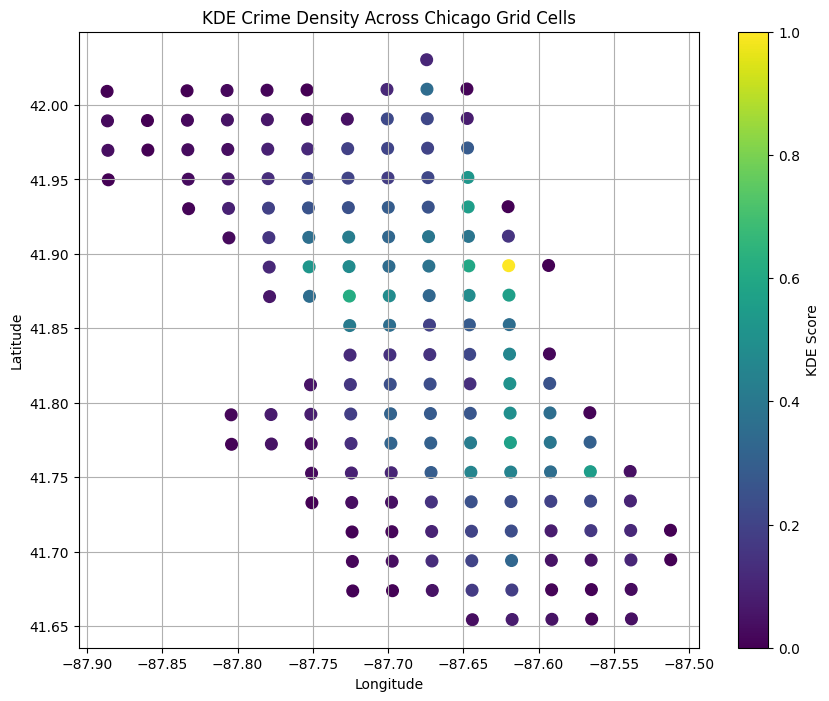

In [107]:
# Step 19.5 — KDE hotspot map

plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    kde_results["GRID_CENTER_LON"],
    kde_results["GRID_CENTER_LAT"],
    c=kde_results["KDE_SCORE"],
    s=70
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("KDE Crime Density Across Chicago Grid Cells")

plt.colorbar(
    scatter,
    label="KDE Score"
)

plt.grid(True)
plt.show()

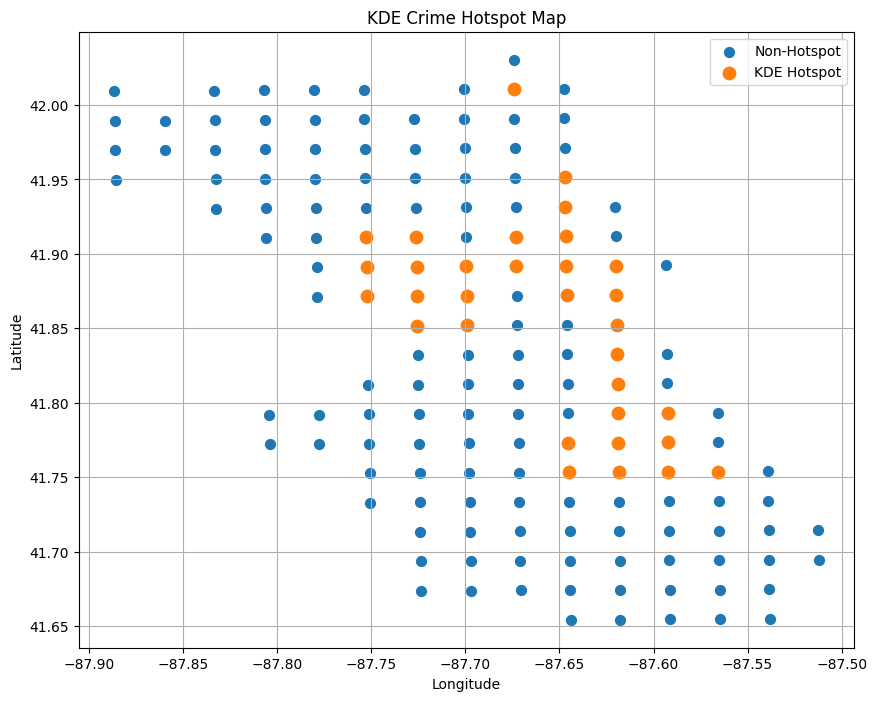

In [108]:
# Step 19.6 — KDE hotspot visualization

plt.figure(figsize=(10, 8))

non_hotspot = kde_results[
    kde_results["KDE_HOTSPOT"] == 0
]

hotspot = kde_results[
    kde_results["KDE_HOTSPOT"] == 1
]

plt.scatter(
    non_hotspot["GRID_CENTER_LON"],
    non_hotspot["GRID_CENTER_LAT"],
    s=50,
    label="Non-Hotspot"
)

plt.scatter(
    hotspot["GRID_CENTER_LON"],
    hotspot["GRID_CENTER_LAT"],
    s=80,
    label="KDE Hotspot"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("KDE Crime Hotspot Map")

plt.legend()
plt.grid(True)
plt.show()

In [109]:
# Step 19.7 — Save final KDE results

kde_results.to_csv(
    "data/kde_results.csv",
    index=False
)

print("Saved: data/kde_results.csv")

Saved: data/kde_results.csv


In [110]:
node_features.to_csv(
    "data/node_features.csv",
    index=False
)

print("Saved successfully!")
print("Shape:", node_features.shape)

Saved successfully!
Shape: (157, 33)


In [111]:
# ============================================
# SAVE PHASE 1 GCN MODEL AND ARTIFACTS
# ============================================

import os
import json
import torch

# Create models directory
os.makedirs("models", exist_ok=True)

# --------------------------------------------
# 1. Restore the BEST model
# --------------------------------------------

model.load_state_dict(best_model_state)
model = model.to(device)
model.eval()

# --------------------------------------------
# 2. Save GCN model checkpoint
# --------------------------------------------

phase1_model_path = "models/phase1_crime_gcn.pth"

torch.save({
    "model_state_dict": best_model_state,

    # Model architecture
    "input_features": X.shape[1],
    "hidden_features": 128,
    "output_classes": len(label_encoder.classes_),
    "dropout": 0.5,

    # Training information
    "best_epoch": best_epoch,
    "best_validation_macro_f1": best_val_f1,

    # Feature information
    "feature_columns": feature_columns,

    # Class labels
    "class_names": label_encoder.classes_.tolist(),

    # Graph information
    "num_nodes": graph_data.num_nodes,
    "num_edges": graph_data.num_edges

}, phase1_model_path)

print("Phase 1 GCN model saved successfully!")
print(f"Path: {phase1_model_path}")

Phase 1 GCN model saved successfully!
Path: models/phase1_crime_gcn.pth


In [112]:
# ============================================
# SAVE PHASE 1 LABEL INFORMATION
# ============================================

phase1_label_info = {
    int(i): class_name
    for i, class_name in enumerate(label_encoder.classes_)
}

label_path = "models/phase1_label_info.json"

with open(label_path, "w") as f:
    json.dump(phase1_label_info, f, indent=4)

print("Phase 1 label information saved!")
print(f"Path: {label_path}")
print("\nLabel mapping:")

for label, name in phase1_label_info.items():
    print(f"{label} -> {name}")

Phase 1 label information saved!
Path: models/phase1_label_info.json

Label mapping:
0 -> ASSAULT
1 -> BATTERY
2 -> CRIMINAL DAMAGE
3 -> DECEPTIVE PRACTICE
4 -> MOTOR VEHICLE THEFT
5 -> SEX OFFENSE
6 -> THEFT


In [113]:
# ============================================
# SAVE PHASE 1 GRAPH STRUCTURE
# ============================================

graph_path = "models/phase1_graph.pt"

torch.save({
    "edge_index": graph_data.edge_index.cpu(),
    "edge_weight": getattr(graph_data, "edge_weight", None),
    "grid_ids": grid_nodes["GRID_ID"].tolist()
}, graph_path)

print("Phase 1 graph structure saved!")
print(f"Path: {graph_path}")

Phase 1 graph structure saved!
Path: models/phase1_graph.pt


In [114]:
# ============================================
# SAVE PHASE 1 NODE FEATURES
# ============================================

node_features_path = "data/phase1_node_features.csv"

node_features.to_csv(
    node_features_path,
    index=False
)

print("Phase 1 node features saved!")
print(f"Path: {node_features_path}")

Phase 1 node features saved!
Path: data/phase1_node_features.csv


In [115]:
import joblib

svm_path = "models/phase1_svm.pkl"

joblib.dump(svm_model, svm_path)

print("Phase 1 SVM saved!")
print(f"Path: {svm_path}")

Phase 1 SVM saved!
Path: models/phase1_svm.pkl


In [116]:
import os

print("Saved Phase 1 files:")
print("--------------------")

for file in os.listdir("models"):
    print("✓", file)

Saved Phase 1 files:
--------------------
✓ phase1_crime_gcn.pth
✓ phase1_graph.pt
✓ phase1_label_info.json
✓ phase1_svm.pkl
✓ phase2_label_info.json
✓ phase2_scaler.pkl
✓ phase2_victimisation_gcn.pth
